In [1]:
import pandas as pd

In [2]:
dataframe = pd.read_csv("uber.csv")

In [3]:
df = dataframe
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
df.dropna(inplace = True)

In [5]:
df.isna().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [6]:
df.drop(["Unnamed: 0", "key"], axis = 1, inplace = True)

In [7]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

{'whiskers': [<matplotlib.lines.Line2D at 0x2a890365a60>,
 'caps': [<matplotlib.lines.Line2D at 0x2a890366060>,
 'boxes': [<matplotlib.lines.Line2D at 0x2a890365790>],
 'medians': [<matplotlib.lines.Line2D at 0x2a890366600>],
 'fliers': [<matplotlib.lines.Line2D at 0x2a8903668d0>],
 'means': []}

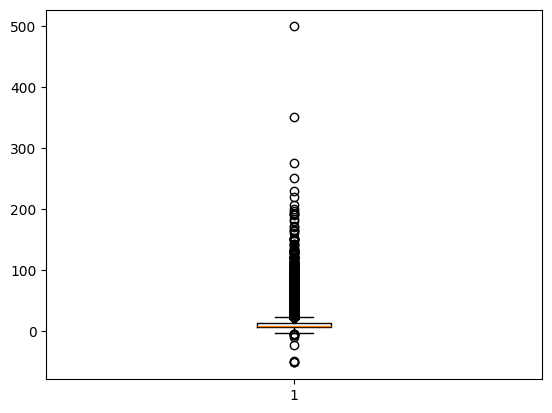

In [8]:
import matplotlib.pyplot as plt
plt.boxplot(df["fare_amount"])

In [9]:
def find_outliers(df):
    q1 = df.quantile(0.25) # 1st Quartile
    q3 = df.quantile(0.75) # 3d Quartile
    IQR = q3-q1 # InterQuartile Range
    outliers = df[(df<q1-1.5*IQR) | (df>q3+1.5*IQR)]
    return outliers

In [10]:
fare_amount_outliers = find_outliers(df["fare_amount"])
print("Number of Outlier : " + str(len(fare_amount_outliers)))
print("Max Outlier : " + str(fare_amount_outliers.max()))
print("Min Outlier : " + str(fare_amount_outliers.min()))

Number of Outlier : 17166
Max Outlier : 499.0
Min Outlier : -52.0


In [ ]:
# Drop the Outliers
q1 = df["fare_amount"].quantile(0.25)
q3 = df["fare_amount"].quantile(0.75)
iqr = q3 - q1
df = df[(df["fare_amount"] < q3+1.5*iqr) & (df["fare_amount"] > q1-1.5*iqr)]

In [12]:
# df.drop(df[df['fare_amount'] < 0].index, inplace = True)

<Axes: >

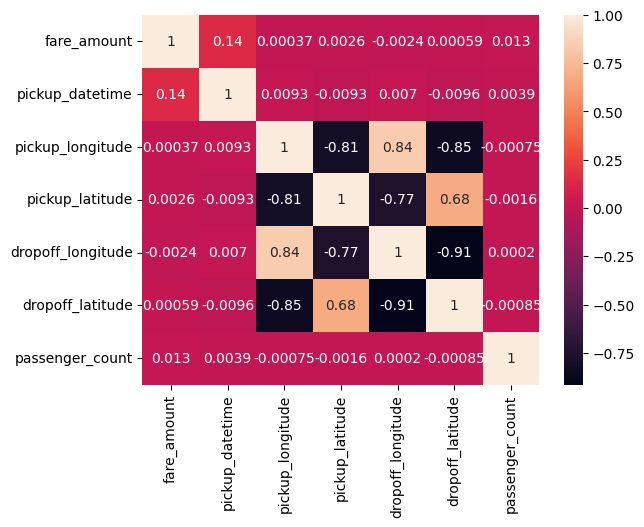

In [13]:
import seaborn as sns
sns.heatmap(df.corr(), annot = True)

In [14]:
x = df.drop("fare_amount", axis = 1) # Independent Set
y = df['fare_amount'] # Target Variable

In [15]:
x['pickup_datetime'] = pd.to_numeric(pd.to_datetime(x['pickup_datetime']))

In [16]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [17]:
from sklearn.linear_model import LinearRegression

lrmodel = LinearRegression()
lrmodel.fit(x_train, y_train) # Fit the Model

LinearRegression()

In [ ]:
predict = lrmodel.predict(x_test)

In [19]:
# Analyze the Metric Scores
from sklearn import metrics
import numpy as np
print(f"Mean absolute error {metrics.mean_absolute_error(y_test, predict)}")
print(f"Mean squared error {metrics.mean_squared_error(y_test, predict)}")
print(f"Root mean squared error {np.sqrt(metrics.mean_squared_error(y_test, predict))}")

Mean absolute error 3.2492280952967945
Mean squared error 16.810552814228927
Root mean squared error 4.1000674158151265


In [20]:
from sklearn.ensemble import RandomForestRegressor

rfmodel = RandomForestRegressor(n_estimators=100,random_state=101)
rfmodel.fit(x_train,y_train)
rfpredict = rfmodel.predict(x_test)

In [21]:
# Analyze th Metric Scores
from sklearn import metrics
import numpy as np
print(f"Mean absolute error {metrics.mean_absolute_error(y_test, rfpredict)}")
print(f"Mean squared error {metrics.mean_squared_error(y_test, rfpredict)}")
print(f"Root mean squared error {np.sqrt(metrics.mean_squared_error(y_test, rfpredict))}")
# print(metrics.r2_score(y_test,predict))

Mean absolute error 1.4280239619511217
Mean squared error 4.440814618364228
Root mean squared error 2.107324042088503
